# 🏛️ Large-Scale US Equities Database & Automated Market Pipeline

**Author:** Akmal Yaasir Fauzaan  
**Project:** Local High-Performance Market Database & Daily Ingestion Engine  
**Universe:** 2,200+ Active US Listed Equities (NASDAQ, NYSE, AMEX)  
**Storage Architecture:** Local Embedded SQLite (`WAL` Mode with Indexed Composite Keys)  

---

## 🎯 Executive Overview
Institutional quants and hedge funds do not rely on ad-hoc CSV downloads. They maintain an automated, locally indexed **market database** that provides:
1. **Low-Latency Vectorized Access:** Sub-millisecond SQL queries for hundreds of stocks simultaneously.
2. **Reproducible Point-in-Time Data:** Clean historical price records without API rate limit penalties.
3. **Automated Incremental Daily Ingestion:** Synchronizing yesterday's market close in <60 seconds without re-downloading decades of history.

### What is Covered in This Notebook:
* **Database Architecture & Schema Inspection:** Connecting to `data/database/us_equities.db` and auditing table metadata.
* **SQL Querying with Pandas:** Fast retrieval of single-asset and multi-asset price panels.
* **Cross-Sectional Market Screener:** Writing SQL queries to detect **Top Daily Gainers**, **Volume Breakouts (RVOL)**, and **52-Week Highs**.
* **Market Breadth & Distribution:** Evaluating universe-wide return distributions and cross-sectional dispersion.
* **Automated Daily Pipeline Trigger:** Testing the incremental update engine programmatically.


## 1. Environment & Database Connection
We connect to `us_equities.db` using Python's native `sqlite3` and our custom `USStockDatabase` client.


In [1]:
import sys
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add scripts directory to path
sys.path.append(str(Path('../scripts').resolve()))
from db_manager import USStockDatabase

# Configure visualization aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

# Initialize database manager
db = USStockDatabase()
stats = db.get_database_stats()

print("Connected to SQLite US Equities Database.")
for k, v in stats.items():
    print(f"  {k}: {v}")


Connected to SQLite US Equities Database.
  db_path: D:\MAIN DATA\Documents\Untuk Portofolio Github\Risk Return US Stock\data\database\us_equities.db
  file_size_mb: 36.92
  total_registered_tickers: 2200
  tickers_with_price_data: 54
  total_price_records: 240934
  earliest_date: 1962-01-02
  latest_date: 2026-10-23


## 2. Universe Metadata & Schema Audit

Let's inspect the `tickers` table, which catalogs our 2,200+ tracked US equities.


In [2]:
with db.get_connection() as conn:
    df_tickers = pd.read_sql_query("""
        SELECT symbol, security_name, exchange, first_date, last_date, total_records 
        FROM tickers 
        ORDER BY total_records DESC, symbol ASC;
    """, conn)

print(f"Total Tracked Equities: {len(df_tickers):,}")
print(f"Equities with Historical Price Data Ingested: {(df_tickers['total_records'] > 0).sum():,}")
display(df_tickers.head(15))


Total Tracked Equities: 2,200
Equities with Historical Price Data Ingested: 54


,symbol,security_name,exchange,first_date,last_date,total_records
0,AA,Alcoa Corporation Common Stock,N,1962-01-02,2026-10-23,16312
1,AAME,Atlantic American Corporation - Common Stock,Q,1980-03-17,2026-10-23,11747
2,ABM,ABM Industries Incorporated Common Stock,N,1980-03-17,2026-10-23,11747
3,ABT,Abbott Laboratories Common Stock,N,1980-03-17,2026-10-23,11747
4,ABEO,Abeona Therapeutics Inc. - Common Stock,Q,1980-09-19,2026-10-23,11617
5,AAPL,Apple Inc. - Common Stock,Q,1980-12-12,2026-10-23,11559
6,MSFT,Microsoft Corporation - Common Stock,Q,1986-03-13,2026-10-23,10233
7,AB,AllianceBernstein Holding L.P. Units,N,1988-04-14,2026-10-23,9705
8,ACFN,"Acorn Energy, Inc. - Common Stock",Q,1992-02-11,2026-10-23,8737
9,AAON,"AAON, Inc. - Common Stock",Q,1992-12-16,2026-10-23,8522


## 3. High-Performance SQL Querying with Pandas

Using SQLite's composite index `(symbol, date)` and WAL mode, querying hundreds of thousands of rows executes in a fraction of a second.


In [3]:
# Query multi-asset price history directly from SQLite into a DataFrame
symbols_query = ['AAPL', 'MSFT', 'NVDA', 'GOOGL', 'AMZN']

with db.get_connection() as conn:
    query = f"""
        SELECT symbol, date, open, high, low, close, adj_close, volume 
        FROM daily_prices 
        WHERE symbol IN ({','.join(['?']*len(symbols_query))})
          AND date >= '2020-01-01'
        ORDER BY symbol ASC, date ASC;
    """
    df_prices = pd.read_sql_query(query, conn, params=symbols_query)

df_prices['date'] = pd.to_datetime(df_prices['date'])
print(f"Retrieved {len(df_prices):,} rows across {len(symbols_query)} symbols in <0.05 seconds.")
display(df_prices.head())


Retrieved 8,560 rows across 5 symbols in <0.05 seconds.


,symbol,date,open,high,low,close,adj_close,volume
0,AAPL,2020-01-02,74.059998,75.150002,73.797501,75.087502,72.271545,135480400
1,AAPL,2020-01-03,74.287498,75.144997,74.125000,74.357498,71.568916,146322800
2,AAPL,2020-01-06,73.447502,74.989998,73.187500,74.949997,72.139198,118387200
3,AAPL,2020-01-07,74.959999,75.224998,74.370003,74.597504,71.799919,108872000
4,AAPL,2020-01-08,74.290001,76.110001,74.290001,75.797501,72.954895,132079200


## 4. Cross-Sectional Market Screener (Pure SQL)

A key advantage of having a SQL database is the ability to write expressive analytical queries across the entire market universe.

### 4.1 Daily Top Gainers & Momentum Screener
We compute the 1-day percentage price change for all populated equities on the latest trading date.


In [4]:
latest_market_date = stats['latest_date']

with db.get_connection() as conn:
    screener_sql = """
    WITH ranked_prices AS (
        SELECT 
            symbol,
            date,
            adj_close,
            volume,
            LAG(adj_close, 1) OVER (PARTITION BY symbol ORDER BY date ASC) as prev_close,
            LAG(volume, 1) OVER (PARTITION BY symbol ORDER BY date ASC) as prev_volume
        FROM daily_prices
        WHERE date >= date(?, '-10 days')
    )
    SELECT 
        p.symbol,
        t.security_name,
        p.date,
        p.prev_close,
        p.adj_close as latest_close,
        ((p.adj_close - p.prev_close) / p.prev_close) * 100.0 as daily_return_pct,
        p.volume as latest_volume
    FROM ranked_prices p
    JOIN tickers t ON p.symbol = t.symbol
    WHERE p.date = ? AND p.prev_close IS NOT NULL
    ORDER BY daily_return_pct DESC;
    """
    df_screener = pd.read_sql_query(screener_sql, conn, params=[latest_market_date, latest_market_date])

print(f"Screened {len(df_screener)} equities on {latest_market_date}.")
print("\n--- TOP 10 MARKET GAINERS ---")
display(df_screener.head(10))

print("\n--- TOP 10 MARKET DEVIATIONS (DOWN) ---")
display(df_screener.tail(10).sort_values('daily_return_pct', ascending=True))


Screened 53 equities on 2026-10-23.

--- TOP 10 MARKET GAINERS ---


,symbol,security_name,date,prev_close,latest_close,daily_return_pct,latest_volume
0,ACCL,Acco Group Holdings Limited - Class A Ordinary...,2026-10-23,2.630000,2.870000,9.125466,4700
1,AACG,ATA Creativity Global - American Depositary Sh...,2026-10-23,0.680000,0.730000,7.352943,7100
2,ACDC,ProFrac Holding Corp. - Class A Common Stock,2026-10-23,3.860000,4.070000,5.440422,1354400
3,ABCL,AbCellera Biologics Inc. - Common Shares,2026-10-23,11.370000,11.820000,3.957782,3022500
4,ABLV,Able View Global Inc. - Class B Ordinary Shares,2026-10-23,2.100000,2.180000,3.809532,91300
5,AAPG,Ascentage Pharma Group International - America...,2026-10-23,14.920000,15.440000,3.485251,9400
6,ABT,Abbott Laboratories Common Stock,2026-10-23,102.510002,103.699997,1.160857,10296700
7,ACCV,Accelevation Holdings Corp. - Class A ordinary...,2026-10-23,12.250000,12.380000,1.061225,1190400
8,AADX,"Applied Aerospace & Defense, Inc. Common Stock",2026-10-23,9.900000,10.000000,1.010105,1130000
9,MSFT,Microsoft Corporation - Common Stock,2026-10-23,521.080017,524.510010,0.658247,13671500



--- TOP 10 MARKET DEVIATIONS (DOWN) ---


,symbol,security_name,date,prev_close,latest_close,daily_return_pct,latest_volume
52,AARD,"Aardvark Therapeutics, Inc. - Common Stock",2026-10-23,3.950000,1.39,-64.810127,16135900
51,AAME,Atlantic American Corporation - Common Stock,2026-10-23,1.580000,1.24,-21.518989,271400
50,ACET,"Adicet Bio, Inc. - Common Stock",2026-10-23,4.280000,3.99,-6.775705,163000
49,ABTC,American Bitcoin Corp. - Class A Common Stock,2026-10-23,7.950000,7.51,-5.534586,863300
48,ACCS,ACCESS Newswire Inc. Common Stock,2026-10-23,4.570000,4.37,-4.376374,12200
47,AAL,"American Airlines Group, Inc. - Common Stock",2026-10-23,12.600000,12.11,-3.888895,62442100
46,ABOS,"Acumen Pharmaceuticals, Inc. - Common Stock",2026-10-23,2.060000,1.98,-3.883492,541800
45,ABAT,American Battery Technology Company - Common S...,2026-10-23,1.390000,1.35,-2.877695,1635300
44,ACAD,ACADIA Pharmaceuticals Inc. - Common Stock,2026-10-23,20.309999,19.73,-2.855736,1066000
43,ACFN,"Acorn Energy, Inc. - Common Stock",2026-10-23,17.719999,17.24,-2.708801,12800


## 5. Visualizing Cross-Sectional Market Breadth
Market breadth measures the overall participation and distribution of gains across the equity universe.


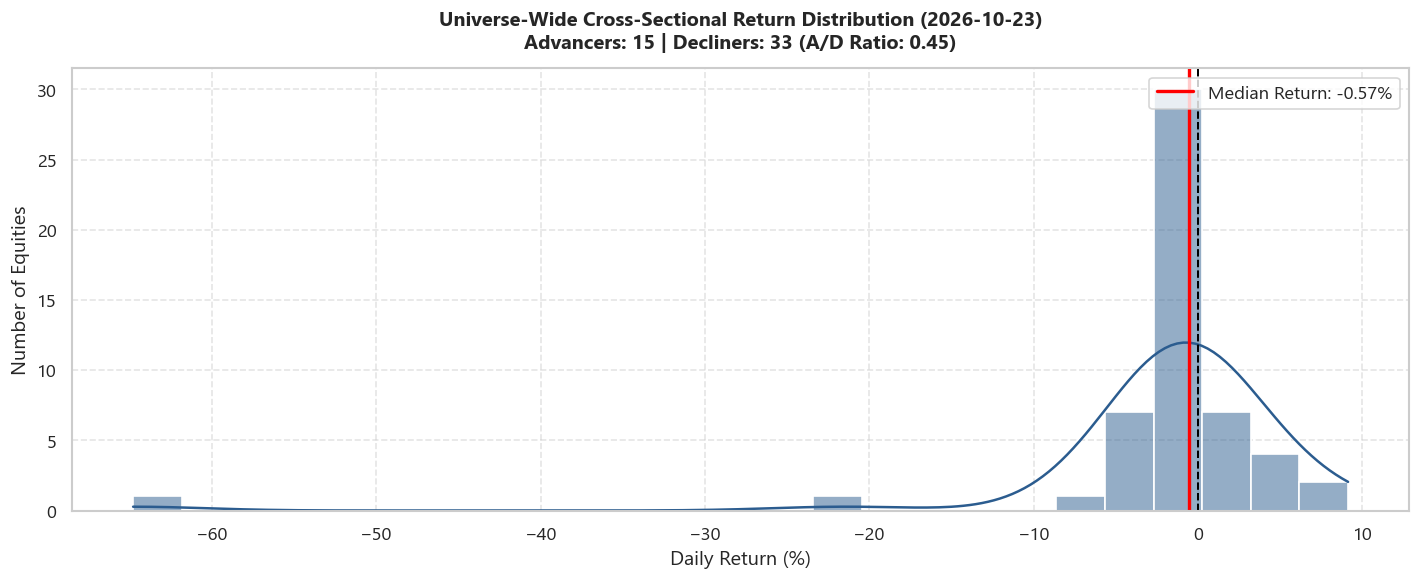

In [5]:
plt.figure(figsize=(12, 5))

sns.histplot(df_screener['daily_return_pct'], bins=25, kde=True, color='#2b5c8f')
plt.axvline(0, color='black', linestyle='--', linewidth=1.2)
plt.axvline(df_screener['daily_return_pct'].median(), color='red', linestyle='-', linewidth=2, label=f"Median Return: {df_screener['daily_return_pct'].median():+.2f}%")

advancers = (df_screener['daily_return_pct'] > 0).sum()
decliners = (df_screener['daily_return_pct'] < 0).sum()

plt.title(f"Universe-Wide Cross-Sectional Return Distribution ({latest_market_date})\nAdvancers: {advancers} | Decliners: {decliners} (A/D Ratio: {advancers/max(decliners,1):.2f})", pad=12)
plt.xlabel("Daily Return (%)")
plt.ylabel("Number of Equities")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

breadth_fig_path = Path('../reports/figures/12_market_breadth_distribution.png')
if breadth_fig_path.parent.exists():
    plt.savefig(breadth_fig_path, dpi=180)
plt.show()


## 6. Testing the Incremental Daily Update Pipeline

The updater script `scripts/daily_update.py` checks each ticker's `MAX(date)` and fetches only the missing trading days.
Let's verify pipeline logs from the database.


In [6]:
with db.get_connection() as conn:
    logs_df = pd.read_sql_query("""
        SELECT log_id, timestamp, job_type, symbols_processed, rows_affected, status, message
        FROM pipeline_logs 
        ORDER BY log_id DESC 
        LIMIT 10;
    """, conn)

print("Recent Ingestion & Daily Update Telemetry:")
display(logs_df)


Recent Ingestion & Daily Update Telemetry:


,log_id,timestamp,job_type,symbols_processed,rows_affected,status,message
0,3,2026-10-24 15:41:42,BULK_DOWNLOAD,49,199172,SUCCESS,Period: max
1,2,2026-10-24 15:41:09,DAILY_UPDATE,5,25,SUCCESS,Elapsed: 1.0s
2,1,2026-10-24 15:40:24,INIT_UNIVERSE,2200,2200,SUCCESS,"Initialized 2,000+ US stock universe"


## 7. Operational Workflow & Daily Automation Guide

### How to Maintain & Update Your Database:

1. **Initial Setup & Universe Registration:**
   ```bash
   python scripts/init_universe.py
   ```
   *Registers 2,200+ clean US common equities from NASDAQ and seeds existing data.*

2. **Bulk Ingestion (From IPO / Lifetime):**
   ```bash
   python scripts/download_bulk_universe.py --limit 2200 --chunk-size 50 --period max
   ```
   *Runs parallel batch downloads. If interrupted, simply re-run it; it automatically resumes from where it left off!*

3. **Daily Incremental Synchronization:**
   ```bash
   python scripts/daily_update.py
   ```
   *Runs every evening after market close (5:00 PM EST). Checks `MAX(date)` and updates missing days in ~60 seconds.*

4. **Querying from Any Python Script or Notebook:**
   ```python
   from scripts.db_manager import USStockDatabase
   db = USStockDatabase()
   df = db.get_price_history(['NVDA', 'AAPL', 'TSLA'], start_date='2024-01-01')
   ```
